### Heart Disease Prediction with Decision Tree

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df=pd.read_csv('heart.csv')

In [ ]:
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1


In [ ]:
df.isna().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


### Data Overview

Let's get a general understanding of the `df` dataset, including its structure, data types, and basic descriptive statistics.

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB
None


In [ ]:
display(df.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
df.duplicated().sum()

np.int64(723)

### Check for Duplicated Data

Let's identify and count any duplicate rows in the DataFrame.

In [ ]:
# Check for duplicated rows
duplicated_rows = df[df.duplicated()]

if not duplicated_rows.empty:
    print(f"Number of duplicated rows: {len(duplicated_rows)}")
    print("Duplicated rows (first 5):")
    display(duplicated_rows.head())
else:
    print("No duplicated rows found in the dataset.")

Number of duplicated rows: 723
Duplicated rows (first 5):


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
15,34,0,1,118,210,0,1,192,0,0.7,2,0,2,1
31,50,0,1,120,244,0,1,162,0,1.1,2,0,2,1
43,46,1,0,120,249,0,0,144,0,0.8,2,0,3,0
55,55,1,0,140,217,0,1,111,1,5.6,0,0,3,0
61,66,0,2,146,278,0,0,152,0,0.0,1,1,2,1


### Removing Duplicated Data

Let's remove the identified duplicated rows to clean the dataset before proceeding with modeling.

In [ ]:
initial_rows = len(df)
df_cleaned = df.drop_duplicates().reset_index(drop=True)
removed_rows = initial_rows - len(df_cleaned)

print(f"Initial number of rows: {initial_rows}")
print(f"Number of duplicated rows removed: {removed_rows}")
print(f"Number of rows after removing duplicates: {len(df_cleaned)}")

display(df_cleaned.head())

Initial number of rows: 1025
Number of duplicated rows removed: 723
Number of rows after removing duplicates: 302


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


### EDA on Cleaned Data

#### Distribution of Target Variable in Cleaned Data

Let's check the balance of the target variable in our cleaned dataset.

target
1    164
0    138
Name: count, dtype: int64


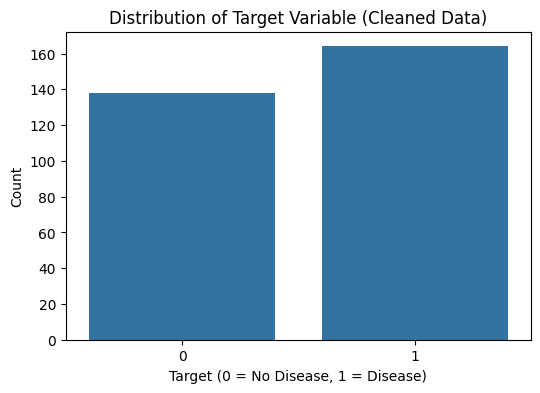

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print(df_cleaned['target'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df_cleaned)
plt.title('Distribution of Target Variable (Cleaned Data)')
plt.xlabel('Target (0 = No Disease, 1 = Disease)')
plt.ylabel('Count')
plt.show()

#### Correlation Heatmap for Cleaned Data

Let's visualize the correlation between all numerical features in the cleaned dataset to identify any strong relationships.

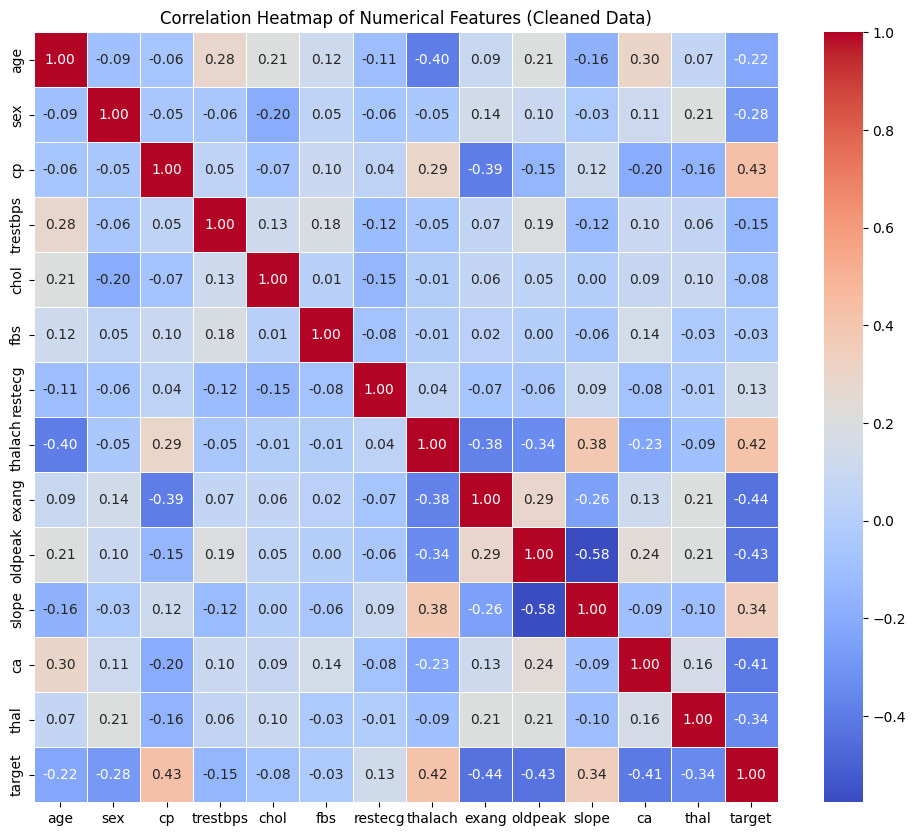

In [ ]:
# Select only numerical columns for correlation calculation from df_cleaned
numerical_df_cleaned = df_cleaned.select_dtypes(include=['int64', 'float64'])

# Calculate the correlation matrix
corr_matrix_cleaned = numerical_df_cleaned.corr()

# Plotting the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix_cleaned, annot=True, cmap='coolwarm', fmt='.2f', linewidths=.5)
plt.title('Correlation Heatmap of Numerical Features (Cleaned Data)')
plt.show()

#### Boxplots of Numerical Features for Cleaned Data

Let's visualize the distribution of each numerical feature using boxplots to identify spread and potential outliers in the cleaned dataset.

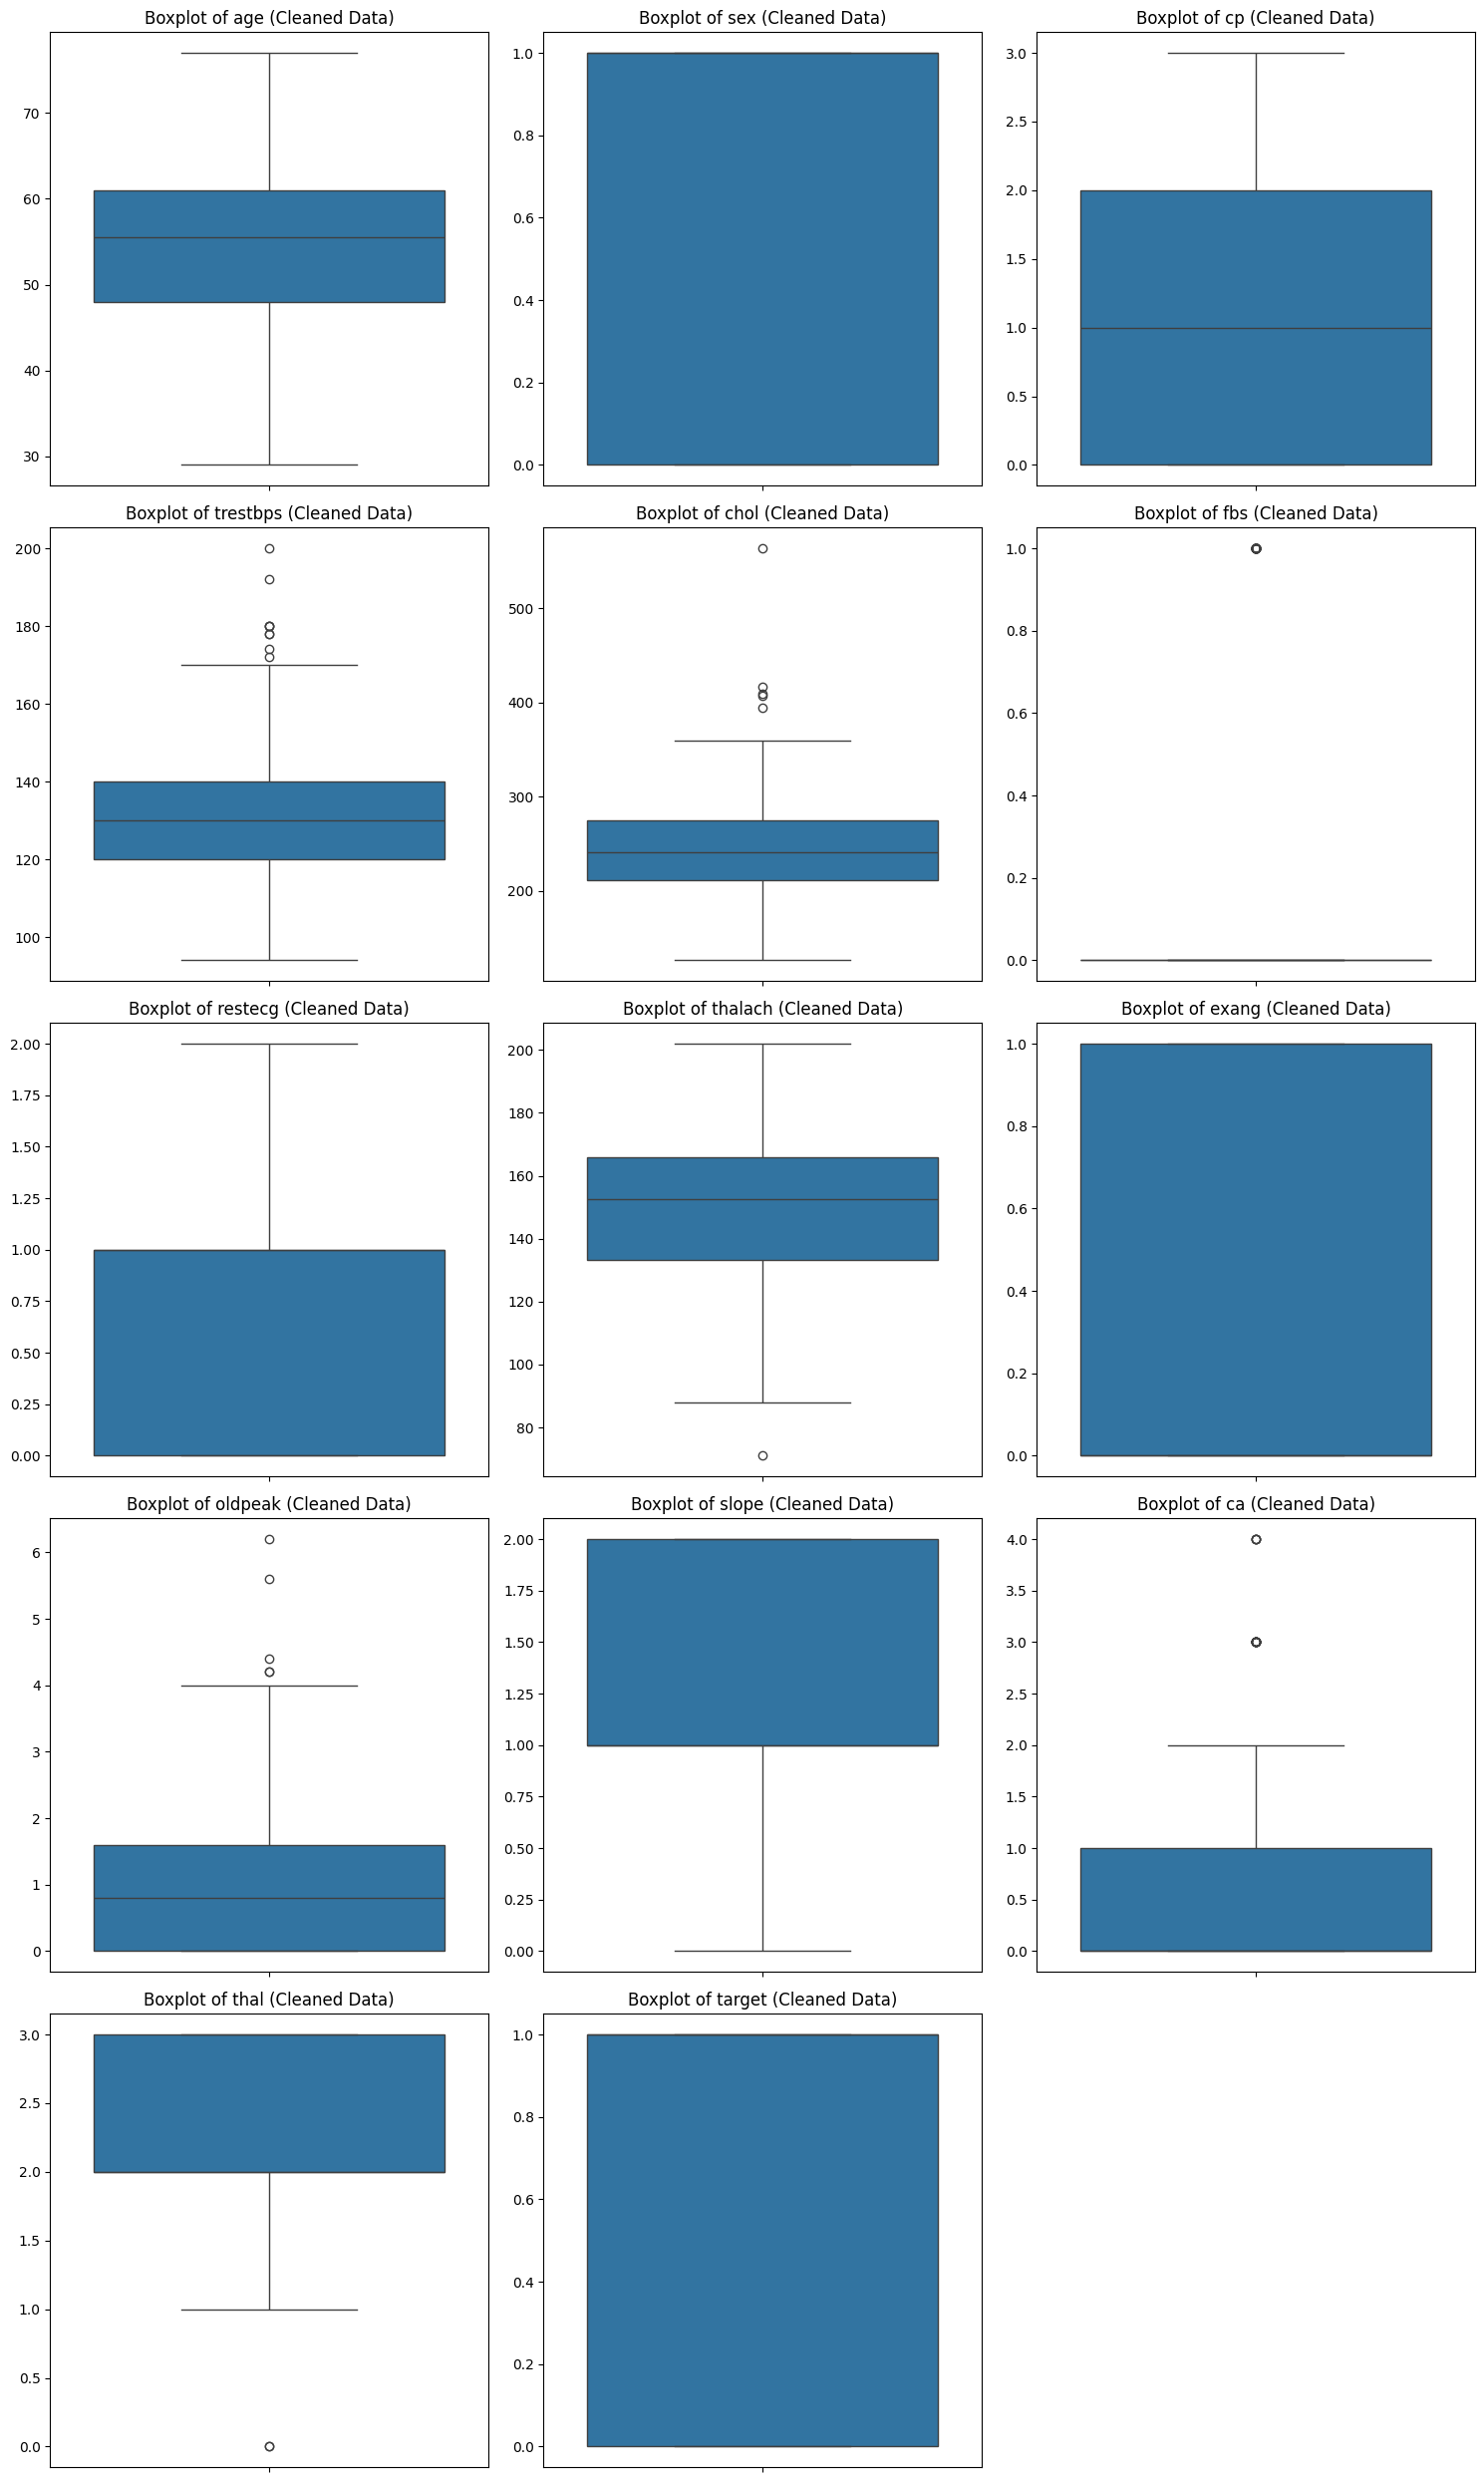

In [ ]:
# Select only numerical columns for boxplots from df_cleaned
numerical_cols_cleaned = df_cleaned.select_dtypes(include=['int64', 'float64']).columns

# Determine the number of rows and columns for the subplot grid
num_cols = len(numerical_cols_cleaned)
num_rows = (num_cols + 2) // 3  # Aim for 3 columns per row

plt.figure(figsize=(15, 5 * num_rows))
for i, col in enumerate(numerical_cols_cleaned):
    plt.subplot(num_rows, 3, i + 1)
    sns.boxplot(y=df_cleaned[col])
    plt.title(f'Boxplot of {col} (Cleaned Data)')
    plt.ylabel('') # Remove y-label to avoid clutter
plt.tight_layout()
plt.show()

### Applying Decision Tree on Cleaned Data

Let's apply a Decision Tree classifier to the cleaned dataset and evaluate its performance.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure df_cleaned is defined
df_cleaned = df.drop_duplicates().reset_index(drop=True)

# Separate features (X_cleaned) and target (y_cleaned) from the cleaned DataFrame
# Re-including 'slope' and 'fbs' columns
X_cleaned = df_cleaned.drop('target', axis=1)
y_cleaned = df_cleaned['target']

# Split the cleaned data into training and testing sets
X_train_cleaned, X_test_cleaned, y_train_cleaned, y_test_cleaned = train_test_split(X_cleaned, y_cleaned, test_size=0.2, random_state=42, stratify=y_cleaned)

# Scale numerical features for cleaned data
scaler_cleaned = StandardScaler()
X_train_scaled_cleaned = scaler_cleaned.fit_transform(X_train_cleaned)
X_test_scaled_cleaned = scaler_cleaned.transform(X_test_cleaned)

# Initialize and train the Decision Tree Classifier
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train_scaled_cleaned, y_train_cleaned)

print("Decision Tree model trained successfully on cleaned data.")

Decision Tree model trained successfully on cleaned data.


### Evaluate the Decision Tree Model Performance

Classification Report (Decision Tree - Cleaned Data - All Features):
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61

Confusion Matrix (Decision Tree - Cleaned Data - All Features):
[[22  6]
 [ 6 27]]


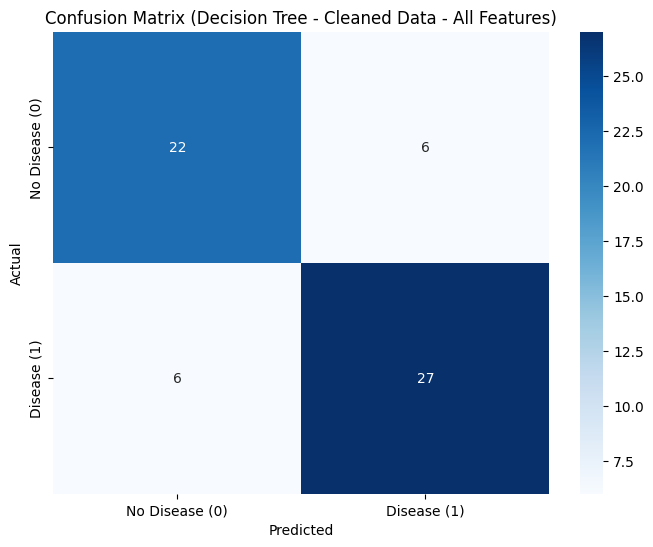

Accuracy (Decision Tree - Cleaned Data - All Features): 0.8033


In [ ]:
y_pred_dt = model_dt.predict(X_test_scaled_cleaned)

print("Classification Report (Decision Tree - Cleaned Data - All Features):")
print(classification_report(y_test_cleaned, y_pred_dt))

print("Confusion Matrix (Decision Tree - Cleaned Data - All Features):")
cm_dt = confusion_matrix(y_test_cleaned, y_pred_dt)
print(cm_dt)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease (0)', 'Disease (1)'],
            yticklabels=['No Disease (0)', 'Disease (1)'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Decision Tree - Cleaned Data - All Features)')
plt.show()

accuracy_dt = accuracy_score(y_test_cleaned, y_pred_dt)
print(f"Accuracy (Decision Tree - Cleaned Data - All Features): {accuracy_dt:.4f}")

### Feature Importance of Decision Tree Model

Let's visualize the importance of each feature in the Decision Tree model to understand their impact on predictions.

In [ ]:
# Get feature importances from the trained Decision Tree model
feature_importances = model_dt.feature_importances_

# Get feature names from X_cleaned
feature_names = X_cleaned.columns

# Create a DataFrame for better visualization
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})

# Sort the DataFrame by importance in descending order
importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Display the feature importances
print("Feature Importances from Decision Tree Model:")
display(importance_df)

Feature Importances from Decision Tree Model:


,Feature,Importance
2,cp,0.331364
11,ca,0.102412
12,thal,0.101465
3,trestbps,0.096783
4,chol,0.096064
9,oldpeak,0.079813
6,restecg,0.052025
8,exang,0.038520
0,age,0.036734
1,sex,0.032969


In [ ]:
import pickle

# Dump df_cleaned using pickle
with open('heart-disease-model.pkl', 'wb') as f:
    pickle.dump(model_dt, f)

print("df_cleaned has been successfully dumped to 'heart disease major.pkl'")

df_cleaned has been successfully dumped to 'heart disease major.pkl'


In [ ]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'],
      dtype='object')

In [ ]:
df['sex'].value_counts()


,count
sex,
1,713
0,312


In [ ]:
import pandas as pd


print("restecg mode :", df['restecg'].mode()[0])
print("exang mode   :", df['exang'].mode()[0])
print("oldpeak mean :", df['oldpeak'].mean())
print("slope mode   :", df['slope'].mode()[0])
print("ca mode      :", df['ca'].mode()[0])
print("thal mode    :", df['thal'].mode()[0])


restecg mode : 1
exang mode   : 0
oldpeak mean : 1.0715121951219515
slope mode   : 1
ca mode      : 0
thal mode    : 2


sex col 1=male and 0=female


In [ ]:
pickle.dump(scaler_cleaned,open("heart_disease_scaler.pkl","wb"))

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pickle
import pandas as pd

df = pd.read_csv("heart.csv")  # replace with your csv filename

X = df.drop('target', axis=1)
y = df['target']

# Scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train with max_depth limited — prevents overfitting and gives proper probabilities
model = DecisionTreeClassifier(
    max_depth=5,        # ✅ limit depth — key fix
    min_samples_leaf=10,
    random_state=42
)
model.fit(X_scaled, y)

# Check accuracy
from sklearn.metrics import accuracy_score
y_pred = model.predict(X_scaled)
print("Accuracy:", accuracy_score(y, y_pred))

# Check probabilities — should no longer be 0.0 or 1.0
print("Sample proba:", model.predict_proba(X_scaled[:5]))

# Save new model and scaler
# pickle.dump(model, open("heart_disease_model.pkl", "wb"))
# pickle.dump(scaler, open("heart_disease_scaler.pkl", "wb"))
print("Model and scaler saved successfully!")

Accuracy: 0.9053658536585366
Sample proba: [[1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]
 [1. 0.]]
Model and scaler saved successfully!


In [ ]:
# Test with known samples
positive_sample = pd.DataFrame([{
    'age': 58.0, 'sex': 0.0, 'cp': 0.0, 'trestbps': 100.0,
    'chol': 248.0, 'fbs': 0.0, 'restecg': 0.0, 'thalach': 122.0,
    'exang': 0.0, 'oldpeak': 1.0, 'slope': 1.0, 'ca': 0.0, 'thal': 2.0
}])

negative_sample = pd.DataFrame([{
    'age': 52.0, 'sex': 1.0, 'cp': 0.0, 'trestbps': 125.0,
    'chol': 212.0, 'fbs': 0.0, 'restecg': 1.0, 'thalach': 168.0,
    'exang': 0.0, 'oldpeak': 1.0, 'slope': 2.0, 'ca': 2.0, 'thal': 3.0
}])

pos_scaled = scaler.transform(positive_sample)
neg_scaled = scaler.transform(negative_sample)

print("Positive proba:", model.predict_proba(pos_scaled))  # should be like [0.2, 0.8]
print("Negative proba:", model.predict_proba(neg_scaled))  # should be like [0.7, 0.3]

Positive proba: [[0. 1.]]
Negative proba: [[1. 0.]]


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import pickle
import pandas as pd

df = pd.read_csv("heart.csv")  # replace with your csv filename

X = df.drop('target', axis=1)
y = df['target']

# Split first then scale — correct approach
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# Train Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_leaf=10,
    random_state=42
)
model.fit(X_train_scaled, y_train)

# Check accuracy
y_pred = model.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Check probabilities — must NOT be exact 0 or 1
print("\nSample probas from test set:")
print(model.predict_proba(X_test_scaled[:5]))

# Test with known samples
positive_sample = pd.DataFrame([{
    'age': 58.0, 'sex': 0.0, 'cp': 0.0, 'trestbps': 100.0,
    'chol': 248.0, 'fbs': 0.0, 'restecg': 0.0, 'thalach': 122.0,
    'exang': 0.0, 'oldpeak': 1.0, 'slope': 1.0, 'ca': 0.0, 'thal': 2.0
}])

negative_sample = pd.DataFrame([{
    'age': 52.0, 'sex': 1.0, 'cp': 0.0, 'trestbps': 125.0,
    'chol': 212.0, 'fbs': 0.0, 'restecg': 1.0, 'thalach': 168.0,
    'exang': 0.0, 'oldpeak': 1.0, 'slope': 2.0, 'ca': 2.0, 'thal': 3.0
}])

pos_scaled = scaler.transform(positive_sample)
neg_scaled = scaler.transform(negative_sample)

print("\nPositive proba:", model.predict_proba(pos_scaled))
print("Negative proba:", model.predict_proba(neg_scaled))

+

Accuracy: 0.8536585365853658

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.79      0.84       102
           1       0.82      0.91      0.86       103

    accuracy                           0.85       205
   macro avg       0.86      0.85      0.85       205
weighted avg       0.86      0.85      0.85       205


Sample probas from test set:
[[0.17030966 0.82969034]
 [0.13360579 0.86639421]
 [0.96845746 0.03154254]
 [0.04983429 0.95016571]
 [0.85732981 0.14267019]]

Positive proba: [[0.27431361 0.72568639]]
Negative proba: [[0.75636631 0.24363369]]


In [ ]:
# Save new model and scaler
pickle.dump(model, open("heart_disease_RF_model.pkl", "wb"))
pickle.dump(scaler, open("heart_disease_scaler_RF.pkl", "wb"))
print("\n✅ Model and scaler saved successfully!")


✅ Model and scaler saved successfully!
